## Setup

In [1]:
# import basic packages
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import PIL
import torch

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("sumn2u/garbage-classification-v2")

print("Path to dataset files:", path)

/opt/anaconda3/envs/CLIP_env_312/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Path to dataset files: /Users/lionellopenoni/.cache/kagglehub/datasets/sumn2u/garbage-classification-v2/versions/12


In [3]:
from datasets import load_dataset
dataset = load_dataset(path + "/standardized_384", split="train")

labels = dataset.features["label"].names
print(f"Labels: {labels}")
print(f"Number of images: {dataset.num_rows}")

Labels: ['battery', 'biological', 'cardboard', 'clothes', 'glass', 'metal', 'paper', 'plastic', 'shoes', 'trash']
Number of images: 12259


In [4]:
def count_observations(dataset):
    labels = dataset.features["label"].names
    label_counts = {label: dataset["label"].count(labels.index(label)) for label in labels}
    label_counts = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"]).reset_index(names="label")
    return label_counts

label_counts = count_observations(dataset)

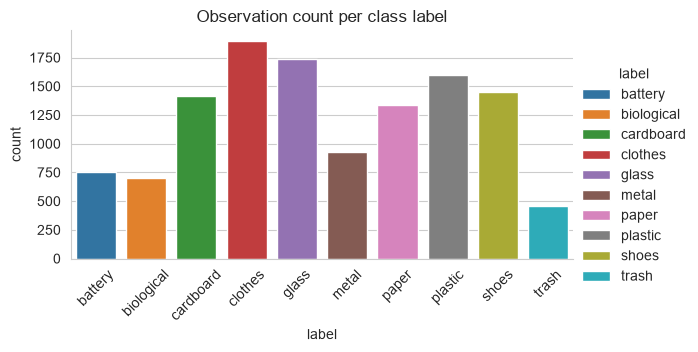

In [5]:
import seaborn as sns

sns.set_style("whitegrid")
sns.catplot(label_counts, x="label", y="count", kind="bar", hue="label", legend=True, height=3, aspect=2)
plt.xticks(rotation=45)
plt.title("Observation count per class label")
plt.show()

In [6]:
# Split dataset into train and test
data_split = dataset.train_test_split(test_size=0.2, shuffle=True, seed=42, stratify_by_column="label")
train = data_split["train"]
test = data_split["test"]
print("Train Split:\n", count_observations(train))
print("\nTest Split:\n", count_observations(test))

Train Split:
         label  count
0     battery    605
1  biological    559
2   cardboard   1129
3     clothes   1513
4       glass   1389
5       metal    744
6       paper   1069
7     plastic   1278
8       shoes   1159
9       trash    362

Test Split:
         label  count
0     battery    151
1  biological    140
2   cardboard    282
3     clothes    379
4       glass    347
5       metal    186
6       paper    267
7     plastic    319
8       shoes    290
9       trash     91


In [7]:
# process images in test split
from transformers import CLIPImageProcessor
image_processor = CLIPImageProcessor.from_pretrained("openai/clip-vit-base-patch32")

def preprocess_images(examples):
    images = examples["image"]
    inputs = image_processor(images, return_tensors="pt")
    examples["pixel_values"] = inputs["pixel_values"]
    return examples

test = test.map(preprocess_images, batched=True, remove_columns=["image"])

### Utility functions for prediction and evaluation

In [10]:
from transformers import AutoTokenizer
from transformers import CLIPModel
from torch.utils.data import DataLoader
from typing import List
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

def predict_processed_dataset(dataset=test, text=labels, tokenize_text=True):
    """Predict preprocessed images in a dataset with a defined label-set
    
    Parameters
    ----------
    dataset : Dataset = test
        The dataset containing preprocessed image data to predict on. Must have a column "pixel_values".
        By default, predict on dataset stored as "test".
    text : List = labels
        The set of text labels used for the classification. Can be raw labels or label embeddings.
        When using tokenized labels, they should be computed with openai/clip-vit-base-patch32, and the tokenize_text parameter set to False.
        Defaults to variable "labels".
    tokenize_text : bool = True
        Whether or not to tokenize the List of labels passed in "text"-argument.

    Returns
    -------
    predictions : List
        A list with predictions for images from the dataset as integers corresponding to the indexes for the list passed in "text"-argument.
    """
    # encode text labels
    tokenizer = AutoTokenizer.from_pretrained("openai/clip-vit-base-patch32")
    if tokenize_text:
        text_inputs = tokenizer(text=text, return_tensors="pt", padding=True)
    else: text_inputs = text

    # instantiate model
    model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32")

    # create DataLoader for processing in batches
    dataset.set_format("torch", columns=["pixel_values"], output_all_columns=True)
    loader = DataLoader(dataset, batch_size=32, num_workers=4) # type: ignore

    predictions = []

    for batch in loader:
        pixel_values = batch["pixel_values"]
        with torch.no_grad():
            output = model(**text_inputs, pixel_values=pixel_values)
        logits_per_image = output.logits_per_image
        probs = logits_per_image.softmax(dim=1)
        predictions.extend(probs.argmax(dim=1).tolist())

    return predictions

def evaluate_predictions(y_true : List, y_pred : List, target_names=labels):
    """Calculates and prints classification evaluation metrics accuracy, precision, recall, and f1-score and prints the classification report.
    
    Parameters
    ----------
    y_true : List
        List containing the true labels
    y_pred : List
        List containing the predicted labels
    target_names : List
        List of label names to be displayed in the classification report. Defaults to the variable "labels".

    Returns
    -------
    A dictionary with keys "accuracy", "precision", "recall", and "f1", containing the respective metric values
    """
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, average="weighted")

    print(f"\n{"="*60}\nResults:    \n {"="*60}")
    print(f"Accuracy:       {accuracy:.4f}")
    print(f"Precision:      {precision:.4f}")
    print(f"Recall:         {recall:.4f}")
    print(f"F1:             {f1:.4f}")
    print(classification_report(y_true, y_pred, target_names=target_names, zero_division=0))

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

# Plot Confusion Matrix
def plot_conf_matrix(y_true, y_pred):
    ConfusionMatrixDisplay.from_predictions(y_true, y_pred, xticks_rotation=45)
    plt.grid(False)
    plt.show()

## Compute Image Embeddings

In [12]:
from transformers import CLIPVisionModelWithProjection
from torch.utils.data import DataLoader
from transformers import logging as hf_logging
hf_logging.set_verbosity_error() # reduces output when computing image embeddings

vision_model = CLIPVisionModelWithProjection.from_pretrained("openai/clip-vit-base-patch32")

# create DataLoader for processing in batches
test.set_format("torch", columns=["pixel_values"], output_all_columns=True)
loader = DataLoader(test, batch_size=32, num_workers=4) # type: ignore

all_embeds = []

for batch in loader:
    with torch.no_grad():
        outputs = vision_model(batch["pixel_values"])
    image_embeds = outputs.image_embeds
    image_embeds = image_embeds / image_embeds.norm(dim=-1, keepdim=True)

    all_embeds.append(image_embeds)

image_embeddings = torch.cat(all_embeds)


Loading weights: 100%|██████████| 200/200 [00:00<00:00, 54705.93it/s]
